In [15]:
from datasets import load_from_disk
from transformers import AutoTokenizer
import matplotlib.pyplot as plt
import numpy as np

tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [16]:
def analyze_text_lengths(dataset):
    # Combine all paragraphs for each item
    combined_texts = []
    raw_text_lengths = []
    
    for item in dataset:
        combined_text = " ".join([p['text'] for p in item['paragraphs']])
        combined_texts.append(combined_text)
        raw_text_lengths.append(len(combined_text))
    
    # Approximate token lengths based on word counts
    token_lengths = []
    for text in combined_texts:
        word_count = len(text.split())
        estimated_tokens = word_count * 1.5  # Assuming average 1.5 tokens per word
        token_lengths.append(int(estimated_tokens))
    
    return raw_text_lengths, token_lengths, combined_texts

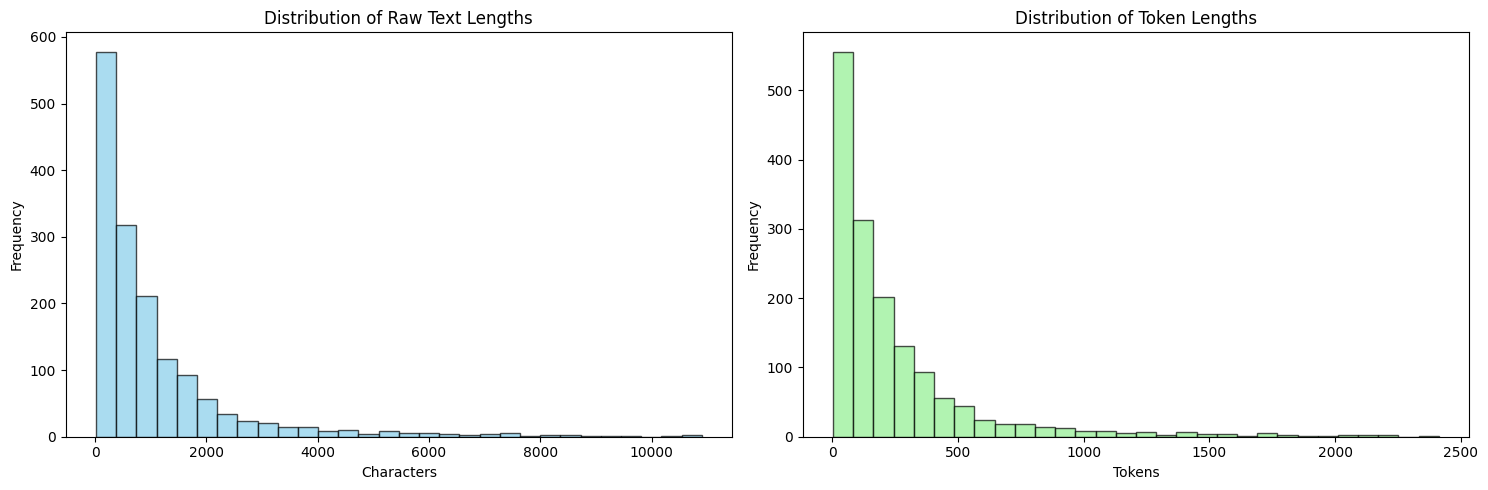


Token length statistics:
50th percentile: 133
90th percentile: 559
95th percentile: 896
99th percentile: 1760
Max length: 2413


In [17]:
data = load_from_disk("/vol/csedu-nobackup/project/lzandbergen-storage/lars-zandbergen-pdf-extraction/data/OA-mine/dataset/category_split")

train_data = data['train']
raw_lengths, token_lengths, texts = analyze_text_lengths(train_data)

# Plot distributions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.hist(raw_lengths, bins=30, alpha=0.7, color='skyblue', edgecolor='black')
ax1.set_title('Distribution of Raw Text Lengths')
ax1.set_xlabel('Characters')
ax1.set_ylabel('Frequency')

ax2.hist(token_lengths, bins=30, alpha=0.7, color='lightgreen', edgecolor='black')
ax2.set_title('Distribution of Token Lengths')
ax2.set_xlabel('Tokens')
ax2.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Calculate statistics
percentiles = np.percentile(token_lengths, [50, 90, 95, 99])
print("\nToken length statistics:")
print(f"50th percentile: {percentiles[0]:.0f}")
print(f"90th percentile: {percentiles[1]:.0f}")
print(f"95th percentile: {percentiles[2]:.0f}")
print(f"99th percentile: {percentiles[3]:.0f}")
print(f"Max length: {max(token_lengths)}")